# Phase 3: Features + classification (kritikaa, patient 22)

Regions inside the liver: **tumour** = each ground-truth tumour blob; **healthy** = dark spots in the liver that are not tumour (max 3 per slice).
Features: shape + GLCM (0/45/90/135 degrees) + first-order HU. Classifier: **random forest** (100 decision trees that vote).

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "kritikaa"
SLICES = f"../data/slices/{NAME}"
ENH = "../phase1/outputs_kritikaa/enhanced"
OUT = "outputs_kritikaa"
FIGS = "../report/figures/kritikaa"
os.makedirs(OUT, exist_ok=True)
slice_ids = sorted(os.path.basename(f).replace("_enh.png", "") for f in glob.glob(f"{ENH}/*_enh.png"))
print(len(slice_ids), "slices")

def load(sid):
    return (np.load(f"{SLICES}/{sid}_ct.npy"), cv2.imread(f"{ENH}/{sid}_enh.png", 0),
            cv2.imread(f"{SLICES}/{sid}_liver.png", 0) > 0, cv2.imread(f"{SLICES}/{sid}_tumour.png", 0) > 0)

from scipy.stats import skew, kurtosis
from skimage.measure import regionprops, label
from skimage.feature import graycomatrix, graycoprops

ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]           # 0, 45, 90, 135 degrees
ANGLE_NAMES = ["0", "45", "90", "135"]

def shape_features(mask):
    r = regionprops(mask.astype(np.uint8))[0]
    area, perim = r.area, max(r.perimeter, 1e-6)
    return {"area": area, "perimeter_area_ratio": perim / area,
            "circularity": 4 * np.pi * area / perim ** 2,      # 1 = perfect circle
            "compactness": perim ** 2 / area,
            "eccentricity": r.eccentricity,                      # 0 = circle, 1 = line
            "solidity": r.solidity}                              # area / convex hull area

def glcm_features(enh, mask, levels=32, per_angle=False):
    """GLCM texture inside the region only (pixels outside the region are ignored)."""
    r = regionprops(mask.astype(np.uint8))[0]
    r0, c0, r1, c1 = r.bbox
    patch, m = enh[r0:r1, c0:c1].astype(int), mask[r0:r1, c0:c1]
    q = np.where(m, 1 + patch * (levels - 1) // 255, 0).astype(np.uint8)   # 1..levels inside, 0 outside
    P = graycomatrix(q, distances=[1], angles=ANGLES, levels=levels + 1)[1:, 1:, :, :].astype(float)
    P = P / np.maximum(P.sum(axis=(0, 1), keepdims=True), 1e-12)
    feats = {}
    for prop in ["energy", "contrast", "homogeneity", "correlation"]:
        vals = np.nan_to_num(graycoprops(P, prop)[0])
        feats.update({f"glcm_{prop}_{a}": v for a, v in zip(ANGLE_NAMES, vals)} if per_angle
                     else {f"glcm_{prop}": vals.mean()})
    ent = [-(P[:, :, 0, k][P[:, :, 0, k] > 0] * np.log2(P[:, :, 0, k][P[:, :, 0, k] > 0])).sum() for k in range(4)]
    feats.update({f"glcm_entropy_{a}": v for a, v in zip(ANGLE_NAMES, ent)} if per_angle
                 else {"glcm_entropy": np.mean(ent)})
    return feats

def first_order_features(ct, mask):
    hu = ct[mask].astype(float)
    return {"mean_HU": hu.mean(), "variance_HU": hu.var(),
            "skewness": skew(hu) if hu.std() > 0 else 0.0,
            "kurtosis": kurtosis(hu) if hu.std() > 0 else 0.0}

def glcm_angle_table(enh, mask):
    t = pd.Series(glcm_features(enh, mask, per_angle=True))
    return pd.DataFrame({a: t[[k for k in t.index if k.endswith("_" + a)]].values for a in ANGLE_NAMES},
                        index=["energy", "contrast", "homogeneity", "correlation", "entropy"]).round(3)

12 slices


In [2]:
MIN_AREA, DARK_K = 10, 1.0
rng = np.random.default_rng(42)

def candidate_spots(enh, liver):
    inner = cv2.erode(liver.astype(np.uint8), np.ones((9, 9), np.uint8)) > 0
    if not inner.any():
        return np.zeros_like(liver)
    dark = (enh < np.median(enh[inner]) - DARK_K * enh[inner].std()) & inner
    return cv2.morphologyEx(dark.astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)) > 0

rois = []
for sid in slice_ids:
    ct, enh, liver, tumour = load(sid)
    for r in regionprops(label(tumour)):
        if r.area >= MIN_AREA:
            m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
            rois.append((sid, m, 1))
    healthy = []
    for r in regionprops(label(candidate_spots(enh, liver))):
        m = np.zeros(tumour.shape, bool); m[tuple(r.coords.T)] = True
        if r.area >= MIN_AREA and not (m & tumour).any():
            healthy.append(m)
    for i in rng.permutation(len(healthy))[:3]:
        rois.append((sid, healthy[i], 0))
labels = np.array([y for _, _, y in rois])
print(len(rois), "regions:", (labels == 1).sum(), "tumour,", (labels == 0).sum(), "healthy")

sid, m, _ = max((r for r in rois if r[2] == 1), key=lambda r: r[1].sum())
print(f"\nGLCM at 4 angles, largest tumour region ({sid}):")
print(glcm_angle_table(load(sid)[1], m))

glcm_example = glcm_angle_table(load(sid)[1], m)
glcm_example.to_csv(f"{FIGS}/{NAME}_glcm_table.csv")

50 regions: 14 tumour, 36 healthy

GLCM at 4 angles, largest tumour region (p22_s132):
                 0     45     90    135
energy       0.182  0.163  0.177  0.161
contrast     1.519  2.411  1.521  2.712
homogeneity  0.604  0.536  0.584  0.501
correlation  0.887  0.813  0.885  0.788
entropy      5.408  5.694  5.458  5.738


In [3]:
cache, rows = {}, []
for sid, m, y in rois:
    if sid not in cache:
        cache[sid] = load(sid)
    ct, enh, _, _ = cache[sid]
    rows.append({"slice": sid, "label": y, **shape_features(m), **glcm_features(enh, m), **first_order_features(ct, m)})
features = pd.DataFrame(rows)
features.to_csv(f"{OUT}/phase3_features.csv", index=False)
print(features.groupby("label").mean(numeric_only=True).T.round(3).rename(columns={0: "healthy", 1: "tumour"}))

label                 healthy   tumour
area                   34.333  672.571
perimeter_area_ratio    0.712    0.289
circularity             1.137    0.630
compactness            13.890   22.525
eccentricity            0.731    0.631
solidity                0.928    0.861
glcm_energy             0.378    0.191
glcm_contrast           1.712    2.082
glcm_homogeneity        0.573    0.565
glcm_correlation        0.174    0.812
glcm_entropy            3.057    5.217
mean_HU                76.909   51.023
variance_HU           246.562  370.158
skewness               -0.175    0.208
kurtosis               -0.270    0.067


In [4]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score, f1_score
import joblib

X = features.drop(columns=["slice", "label"]).values
y = features["label"].values

from sklearn.ensemble import RandomForestClassifier
# random forest: 100 decision trees, each trained on a random sample of regions/features; they vote
model = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42))
idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.3, stratify=y, random_state=42)
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

cv = cross_val_score(model, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=42), scoring="accuracy")
print(f"5-fold cross-validation accuracy: {cv.mean():.3f} (+/- {cv.std():.3f})  folds: {np.round(cv, 3)}")

5-fold cross-validation accuracy: 0.940 (+/- 0.080)  folds: [1.  0.9 1.  0.8 1. ]


Test set: 15 regions (4 tumour, 11 healthy)
  accuracy               0.933
  sensitivity (recall)   1.000
  specificity            0.909
  F1                     0.889


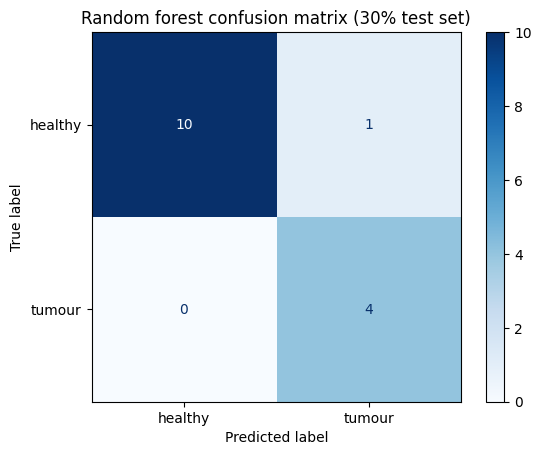

In [5]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()
metrics = {"accuracy": accuracy_score(y_test, y_pred),
           "sensitivity (recall)": tp / (tp + fn) if tp + fn else 0,   # tumours correctly found
           "specificity": tn / (tn + fp) if tn + fp else 0,            # healthy correctly cleared
           "F1": f1_score(y_test, y_pred, zero_division=0)}
print(f"Test set: {len(y_test)} regions ({(y_test == 1).sum()} tumour, {(y_test == 0).sum()} healthy)")
for k, v in metrics.items():
    print(f"  {k:22s} {v:.3f}")
pd.DataFrame([metrics]).to_csv(f"{OUT}/phase3_metrics.csv", index=False)

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=[0, 1]),
                       display_labels=["healthy", "tumour"]).plot(cmap="Blues")
plt.title("Random forest confusion matrix (30% test set)")
plt.savefig(f"{FIGS}/{NAME}_p3_confusion_matrix.png", dpi=120, bbox_inches="tight"); plt.show()

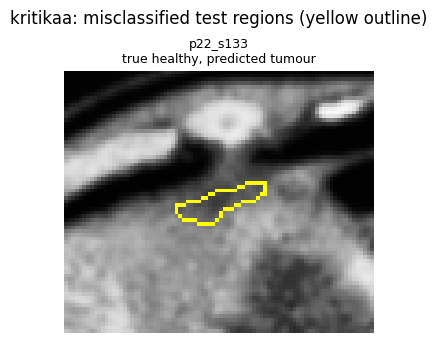

# Phase 3 failed cases: kritikaa

Test set: 15 regions, **1 misclassified**.

| Slice | True | Predicted | Area (px) | Mean HU | Likely reason |
|---|---|---|---|---|---|
| p22_s133 | healthy | tumour | 153 | 41 | healthy dark structure (vessel or organ edge) that looks tumour-like |


In [6]:
# ---- failed cases: the test regions the classifier got wrong ----
FAILED = f"../report/failed_cases/{NAME}"
os.makedirs(FAILED, exist_ok=True)
wrong = idx_test[y_pred != y_test]
names = {0: "healthy", 1: "tumour"}
lines = [f"# Phase 3 failed cases: {NAME}", "",
         f"Test set: {len(y_test)} regions, **{len(wrong)} misclassified**.", "",
         "| Slice | True | Predicted | Area (px) | Mean HU | Likely reason |", "|---|---|---|---|---|---|"]
for i in wrong:
    sid, m, true = rois[i]
    row = features.iloc[i]
    if true == 1 and row["area"] < 100:
        why = "tumour region too small to measure shape/texture reliably"
    elif true == 1:
        why = "tumour looks like normal liver (similar brightness/texture)"
    else:
        why = "healthy dark structure (vessel or organ edge) that looks tumour-like"
    lines.append(f"| {sid} | {names[true]} | {names[1 - true]} | {int(row['area'])} | {row['mean_HU']:.0f} | {why} |")
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(3.4 * len(wrong), 3.6), squeeze=False)
    for a, i in zip(axes[0], wrong):
        sid, m, true = rois[i]
        rgb = cv2.cvtColor(load(sid)[1], cv2.COLOR_GRAY2RGB)
        contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, contours, -1, (255, 255, 0), 1)
        ys, xs = np.where(m)
        y0, y1, x0, x1 = max(ys.min() - 30, 0), ys.max() + 30, max(xs.min() - 30, 0), xs.max() + 30
        a.imshow(rgb[y0:y1, x0:x1]); a.axis("off")
        a.set_title(f"{sid}\ntrue {names[true]}, predicted {names[1 - true]}", fontsize=9)
    plt.suptitle(f"{NAME}: misclassified test regions (yellow outline)")
    plt.tight_layout(); plt.savefig(f"{FAILED}/{NAME}_p3_misclassified.png", dpi=120, bbox_inches="tight"); plt.show()
else:
    lines.append("| - | - | - | - | - | no mistakes in this test split |")
open(f"{FAILED}/{NAME}_phase3_failed_cases.md", "w").write("\n".join(lines))
print("\n".join(lines))

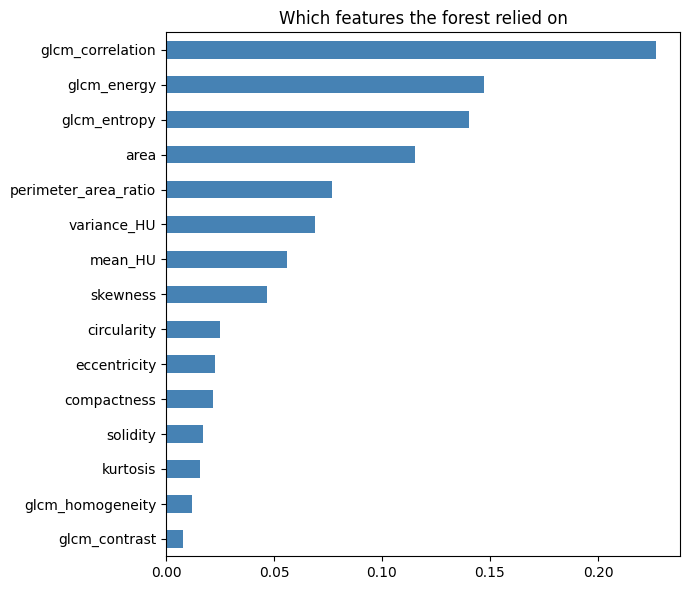

saved model to outputs_kritikaa/rf_model.joblib


In [7]:
model.fit(X, y)
importance = pd.Series(model[-1].feature_importances_, index=features.columns[2:]).sort_values()
importance.plot.barh(figsize=(7, 6), color="steelblue"); plt.title("Which features the forest relied on")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p3_feature_importance.png", dpi=120); plt.show()
joblib.dump({"model": model, "feature_names": list(features.columns[2:])}, f"{OUT}/rf_model.joblib")
print("saved model to", f"{OUT}/rf_model.joblib")